In [2]:
import os
import sys
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

# Add parent directory to path to import local data pipeline modules
sys.path.append(os.path.abspath('..'))

from data.db_connection import load_view, query_to_dataframe
from data.transformations import (
    prepare_time_series_features, 
    categorize_rfm_segments, 
    calculate_pareto_product_impact
)

print("Modules and Database Pipeline Initialized.")

Modules and Database Pipeline Initialized.


In [3]:
# Load Monthly Growth View
df_monthly = load_view("vw_monthly_growth")

# Create Year-Month Display Column
df_monthly['period'] = df_monthly['sales_year'].astype(str) + '-' + df_monthly['sales_month'].astype(str).str.zfill(2)

fig_revenue = px.line(
    df_monthly, 
    x='period', 
    y='current_revenue',
    title='Monthly Revenue Trajectory (2015 - 2017)',
    labels={'period': 'Year-Month', 'current_revenue': 'Total Revenue ($)'},
    markers=True,
    template='plotly_white'
)
fig_revenue.update_traces(line_color='#1f77b4', line_width=2.5)
fig_revenue.show()

In [5]:
# 1. Load raw customer 360 view
df_customers = load_view("vw_customer_360")

# 2. Apply transformations to raw customer data
df_customers_transformed = categorize_rfm_segments(df_customers)

# 3. Aggregate by segment
df_rfm_summary = df_customers_transformed.groupby('rfm_segment', observed=False).agg(
    customer_count=('CustomerKey', 'count'),
    total_revenue=('monetary_value', 'sum'),
    avg_revenue=('monetary_value', 'mean')
).reset_index()

# 4. Plot Chart
fig_rfm = px.bar(
    df_rfm_summary,
    x='rfm_segment',
    y='total_revenue',
    color='avg_revenue',
    title='Revenue Share by Customer RFM Segment',
    labels={'rfm_segment': 'RFM Segment', 'total_revenue': 'Total Revenue ($)', 'avg_revenue': 'Avg Spend / User ($)'},
    color_continuous_scale='Viridis',
    template='plotly_white'
)
fig_rfm.update_layout(xaxis_tickangle=-45)
fig_rfm.show()

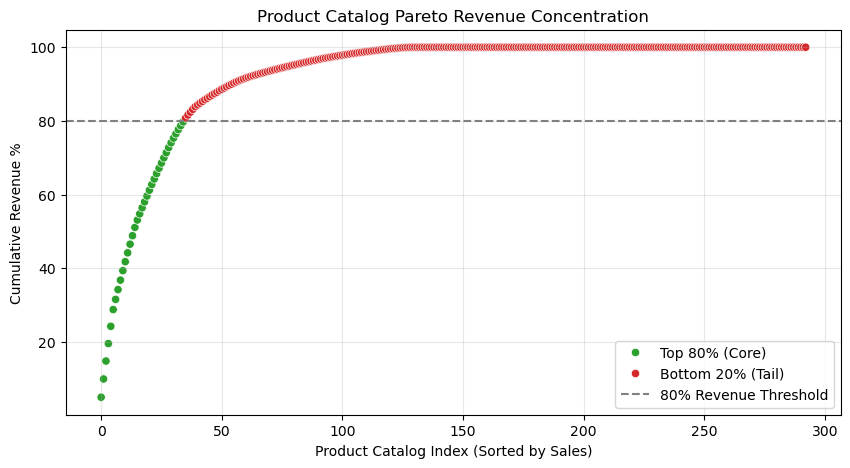

In [6]:
# Extract product performance view and run Pareto transformation
df_products = load_view("vw_product_performance")
df_pareto = calculate_pareto_product_impact(df_products)

# Plot Pareto distribution using Seaborn
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=df_pareto, 
    x=range(len(df_pareto)), 
    y='cum_revenue_pct', 
    hue='pareto_class', 
    palette={'Top 80% (Core)': '#2ca02c', 'Bottom 20% (Tail)': '#d62728'}
)
plt.axhline(80, color='grey', linestyle='--', label='80% Revenue Threshold')
plt.title('Product Catalog Pareto Revenue Concentration')
plt.xlabel('Product Catalog Index (Sorted by Sales)')
plt.ylabel('Cumulative Revenue %')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()